# 2. Разведочный анализ Fashion-MNIST

Источник — [Zalando Research](https://github.com/zalandoresearch/fashion-mnist). 28×28, оттенки серого, 10 классов. Нужны `numpy` и `matplotlib`; SciPy **не требуется**. Перед запуском поместите четыре `.gz`-файла в `CourseWork/data/fashion/` (в текущем проекте они уже загружены).

## 2.1. Пути и проверка наличия файлов

In [ ]:
from pathlib import Path
from IPython.display import display
import gzip
import hashlib
import numpy as np
import matplotlib.pyplot as plt

root = Path.cwd()
if not (root / 'data').exists(): root = root.parent
folder = root / 'data' / 'fashion'
files = ['train-images-idx3-ubyte.gz', 'train-labels-idx1-ubyte.gz',
         't10k-images-idx3-ubyte.gz', 't10k-labels-idx1-ubyte.gz']
for name in files:
    path = folder / name
    assert path.exists(), f'Скачайте {name} из репозитория Fashion-MNIST в {folder}'
    print(name, path.stat().st_size, 'байт')

train-images-idx3-ubyte.gz 26421880 байт
train-labels-idx1-ubyte.gz 29515 байт
t10k-images-idx3-ubyte.gz 4422102 байт
t10k-labels-idx1-ubyte.gz 5148 байт


## 2.2. Чтение файлов IDX
Здесь небольшая функция нужна только для одинакового формата четырёх файлов. Заголовок проверяет количество объектов и размеры.

In [ ]:
def read_idx(path):
    with gzip.open(path, 'rb') as file:
        raw = file.read()
    magic = int.from_bytes(raw[:4], 'big')
    n_dims = magic & 0xff
    shape = tuple(int.from_bytes(raw[4+4*i:8+4*i], 'big') for i in range(n_dims))
    data = np.frombuffer(raw, dtype=np.uint8, offset=4+4*n_dims)
    assert data.size == np.prod(shape), f'Повреждённый файл: {path}'
    return magic, data.reshape(shape)

In [ ]:
image_magic, images = read_idx(folder / files[0])
label_magic, labels = read_idx(folder / files[1])
test_magic, test_images = read_idx(folder / files[2])
_, test_labels = read_idx(folder / files[3])
assert (image_magic, label_magic, test_magic) == (2051, 2049, 2051)
assert images.shape == (60000, 28, 28) and test_images.shape == (10000, 28, 28)
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
print('Train:', images.shape, 'test:', test_images.shape)
print('Диапазон:', int(images.min()), int(images.max()))

Train: (60000, 28, 28) test: (10000, 28, 28)
Диапазон: 0 255


## 2.3. Примеры каждого класса

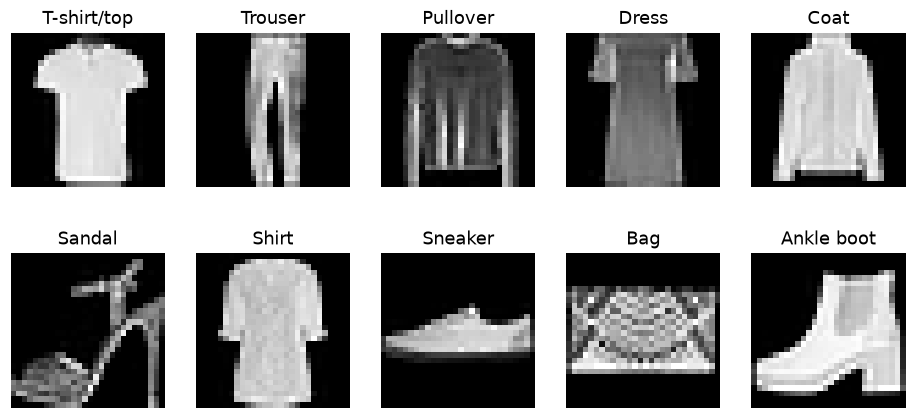

In [ ]:
rng = np.random.default_rng(42)
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for cls, ax in enumerate(axes.ravel()):
    idx = rng.choice(np.flatnonzero(labels == cls))
    ax.imshow(images[idx], cmap='gray', vmin=0, vmax=255)
    ax.set_title(class_names[cls]); ax.axis('off')
display(fig)
plt.close(fig)

## 2.4. Стратифицированное разбиение
Из official train выделяем по 600 изображений каждого класса в validation; test оставляем без изменений.

In [ ]:
rng = np.random.default_rng(42)
val_idx = np.sort(np.concatenate([
    rng.choice(np.flatnonzero(labels == cls), 600, replace=False)
    for cls in range(10)
]))
train_idx = np.setdiff1d(np.arange(len(images)), val_idx)
counts = {
    'train': np.bincount(labels[train_idx], minlength=10).tolist(),
    'val': np.bincount(labels[val_idx], minlength=10).tolist(),
    'test': np.bincount(test_labels, minlength=10).tolist(),
}
print('Размеры:', {k: sum(v) for k, v in counts.items()})
print('Объектов на класс:', counts)

Размеры: {'train': 54000, 'val': 6000, 'test': 10000}
Объектов на класс: {'train': [5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400], 'val': [600, 600, 600, 600, 600, 600, 600, 600, 600, 600], 'test': [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]}


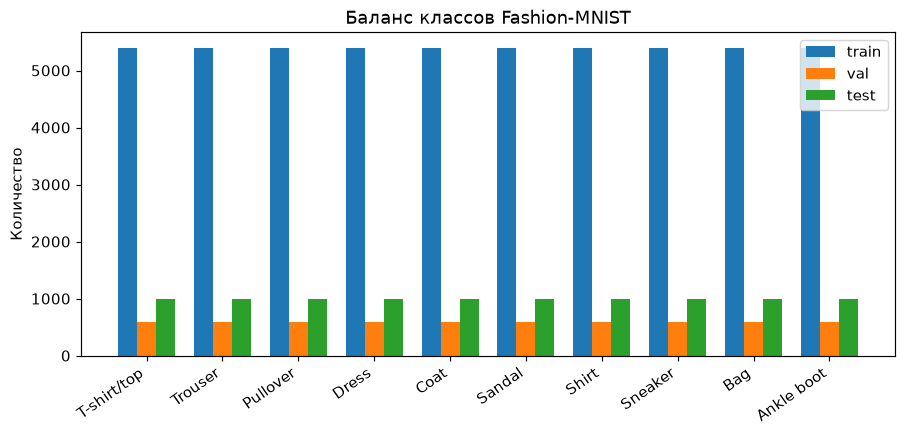

In [ ]:
x = np.arange(10)
fig, ax = plt.subplots(figsize=(10, 4))
for offset, split in [(-.25, 'train'), (0, 'val'), (.25, 'test')]:
    ax.bar(x + offset, counts[split], width=.25, label=split)
ax.set_xticks(x, class_names, rotation=35, ha='right')
ax.set_ylabel('Количество'); ax.set_title('Баланс классов Fashion-MNIST'); ax.legend()
display(fig)
plt.close(fig)

## 2.5. Пиксели и яркость
Статистика только по train после разбиения. Один канал не сопоставим с RGB напрямую.

In [ ]:
train_pixels = images[train_idx]
mean = float(train_pixels.mean() / 255)
std = float(train_pixels.std() / 255)
brightness = train_pixels.mean(axis=(1, 2)) / 255
quantiles = np.quantile(brightness, [0, .01, .5, .99, 1])
print('Среднее [0,1]:', round(mean, 4), 'ст. отклонение:', round(std, 4))
print('Квантили яркости:', np.round(quantiles, 4))

Среднее [0,1]: 0.2858 ст. отклонение: 0.3529
Квантили яркости: [0.0194 0.0637 0.2718 0.5728 0.7522]


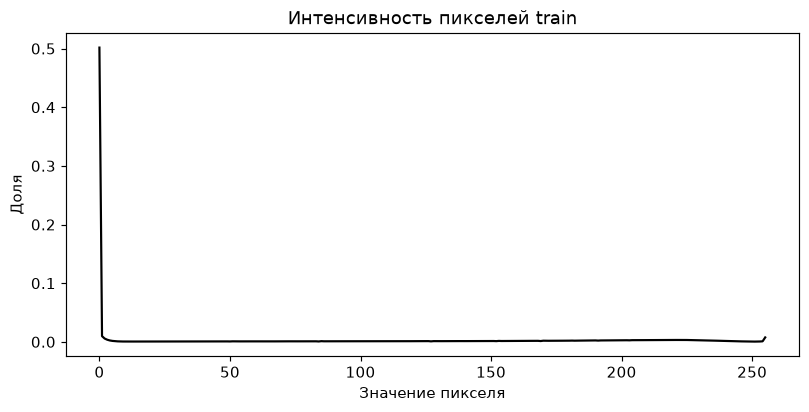

In [ ]:
hist = np.bincount(train_pixels.ravel(), minlength=256)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(256), hist / hist.sum(), color='black')
ax.set(xlabel='Значение пикселя', ylabel='Доля', title='Интенсивность пикселей train')
display(fig)
plt.close(fig)

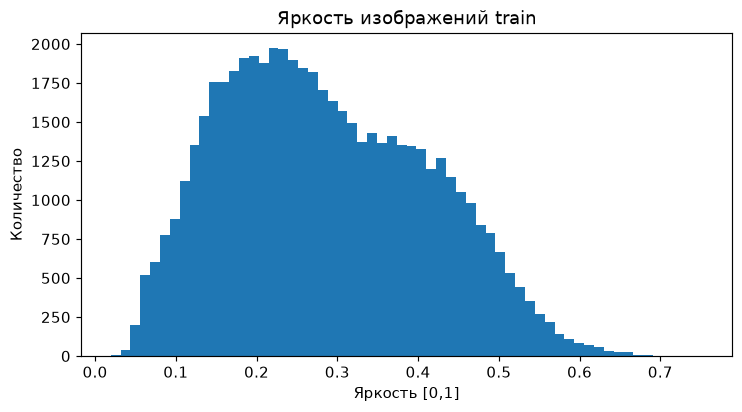

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(brightness, bins=60)
ax.set(xlabel='Яркость [0,1]', ylabel='Количество', title='Яркость изображений train')
display(fig)
plt.close(fig)

## 2.6. Точные повторы и итоговая сводка

In [ ]:
train_hashes = [hashlib.sha256(row.tobytes()).digest() for row in images]
test_hashes = {hashlib.sha256(row.tobytes()).digest() for row in test_images}
duplicates = len(train_hashes) - len(set(train_hashes))
overlap = len(set(train_hashes) & test_hashes)
print('Точные повторы official train:', duplicates)
print('Точные совпадения train/test:', overlap)

Точные повторы official train: 0
Точные совпадения train/test: 0


In [ ]:
summary = {
    'dataset': 'Fashion-MNIST',
    'source': 'https://github.com/zalandoresearch/fashion-mnist',
    'shape': [28, 28, 1], 'dtype': str(images.dtype),
    'pixel_range': [int(images.min()), int(images.max())],
    'class_names': class_names, 'counts_by_class': counts,
    'train_channel_mean_0_1': [mean], 'train_channel_std_0_1': [std],
    'train_brightness_quantiles_0_1': quantiles.tolist(),
    'exact_duplicates_within_official_train': duplicates,
    'exact_train_test_overlap': overlap, 'seed': 42,
}
display(summary)

{'dataset': 'Fashion-MNIST', 'source': 'https://github.com/zalandoresearch/fashion-mnist', 'shape': [28, 28, 1], 'dtype': 'uint8', 'pixel_range': [0, 255], 'class_names': ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'], 'counts_by_class': {'train': [5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400], 'val': [600, 600, 600, 600, 600, 600, 600, 600, 600, 600], 'test': [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]}, 'train_channel_mean_0_1': [0.28584425436841404], 'train_channel_std_0_1': [0.35290784757740723], 'train_brightness_quantiles_0_1': [0.019387755102040816, 0.06374519807923168, 0.2717837134853942, 0.5727751100440178, 0.7522358943577431], 'exact_duplicates_within_official_train': 0, 'exact_train_test_overlap': 0, 'seed': 42}

### Вывод
У Fashion-MNIST большое число объектов и простая структура, но изображения чёрно-белые с однотипным фоном. Это кандидат для простого baseline, не для демонстрации цветной генерации. FID ещё не измерялся.